In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline




In [2]:
# ============================================================
# 1. DATA DESCRIPTION
# ============================================================

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print("\nFirst Five Records:")
print(df.head())

print("\nLast Five Records:")
print(df.tail())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
print(df.describe(include="all").T)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())




DATASET OVERVIEW

First Five Records:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingT

In [3]:
# ============================================================
# 2. DATA CLEANING AND PREPROCESSING
# ============================================================

df.drop_duplicates(inplace=True)

df.drop(columns=["customerID"], inplace=True, errors="ignore")

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df.replace(r"^\s*$", np.nan, regex=True, inplace=True)

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df.dropna(subset=["Churn"], inplace=True)

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

df = df.dropna(subset=["Churn"])

print("\nMissing Values After Initial Cleaning:")
print(df.isnull().sum())

print("\nDataset Shape After Cleaning:", df.shape)





Missing Values After Initial Cleaning:
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Dataset Shape After Cleaning: (7043, 20)


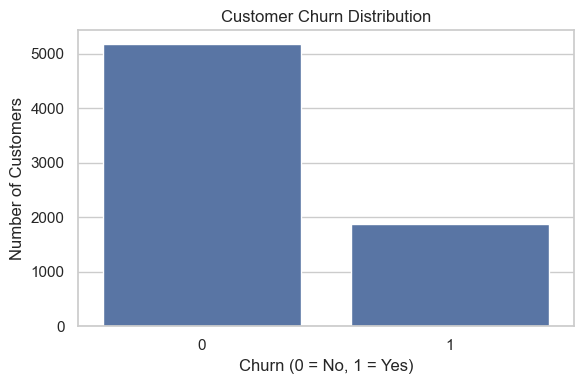

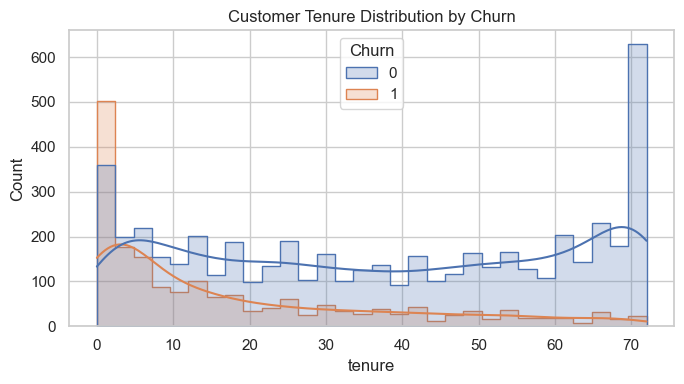

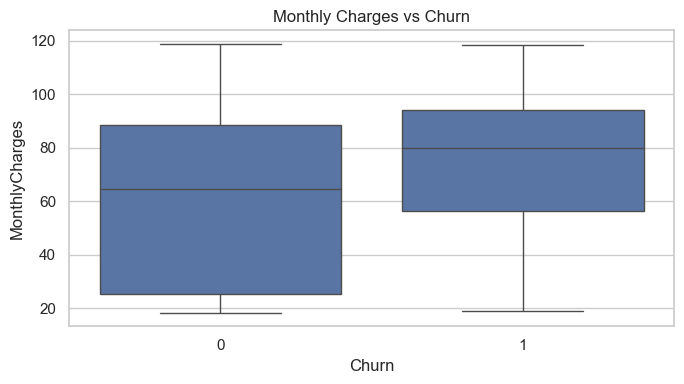

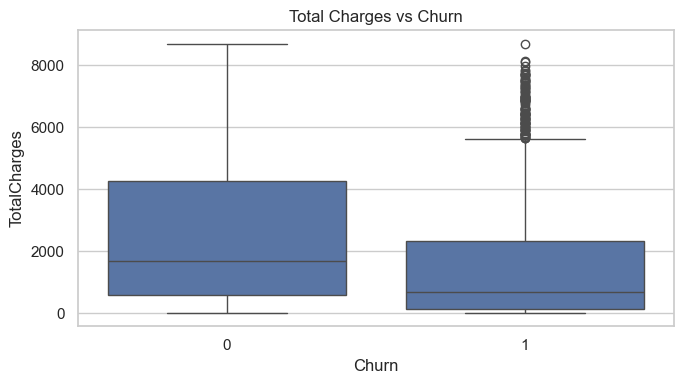

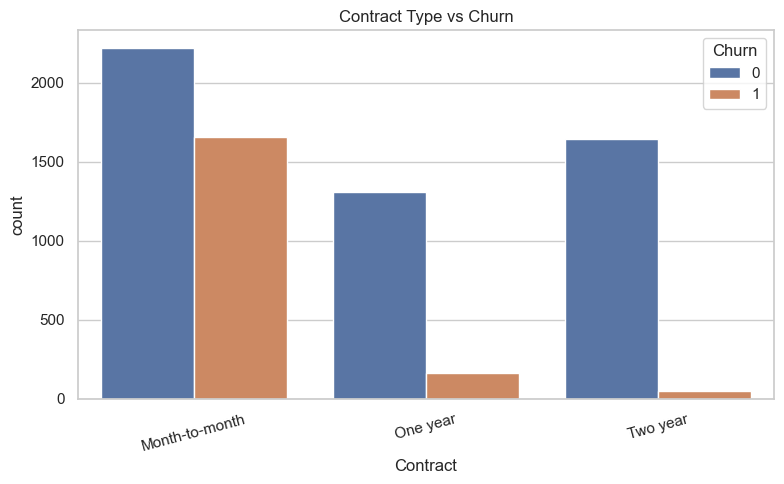

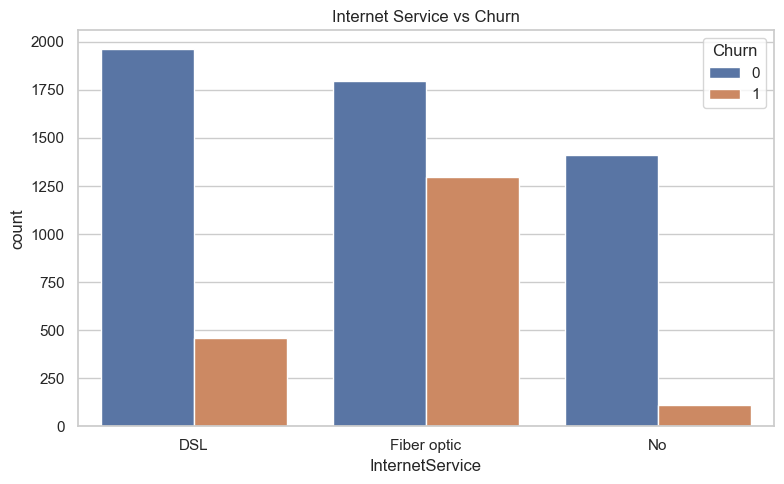

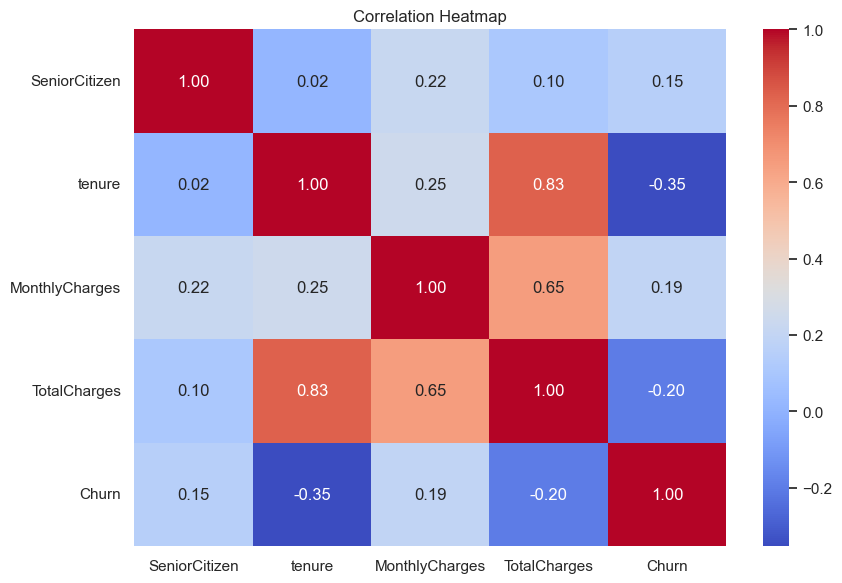

In [4]:
# ============================================================
# 3. EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

sns.set_theme(style="whitegrid")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="tenure", hue="Churn",
             bins=30, kde=True, element="step")
plt.title("Customer Tenure Distribution by Churn")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Churn", y="TotalCharges")
plt.title("Total Charges vs Churn")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Contract Type vs Churn")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Internet Service vs Churn")
plt.tight_layout()
plt.show()

numeric_for_corr = df.select_dtypes(include=np.number)

plt.figure(figsize=(9, 6))
sns.heatmap(numeric_for_corr.corr(), annot=True,
            cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()




In [5]:
# ============================================================
# 4. FEATURE AND TARGET SELECTION
# ============================================================

X = df.drop(columns=["Churn"])
y = df["Churn"].astype(int)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()





In [6]:
# ============================================================
# 5. TRAIN, VALIDATION AND TEST PARTITIONING
# ============================================================

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print("\nDataset Partitioning:")
print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Testing Set:", X_test.shape)



Dataset Partitioning:
Training Set: (4225, 19)
Validation Set: (1409, 19)
Testing Set: (1409, 19)


In [7]:

# ============================================================
# 6. OUTLIER HANDLING
# Winsorization using training-set IQR limits only
# ============================================================

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

outlier_limits = {}

for col in numeric_features:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_limits[col] = (lower, upper)

    X_train[col] = X_train[col].clip(lower, upper)
    X_val[col] = X_val[col].clip(lower, upper)
    X_test[col] = X_test[col].clip(lower, upper)

print("\nOutlier Handling Completed.")




Outlier Handling Completed.


In [8]:

# ============================================================
# 7. ENCODING, IMPUTATION AND STANDARDIZATION
# ============================================================

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])



In [9]:

# ============================================================
# 8. HANDLING CLASS IMBALANCE USING SMOTE
# SMOTE is applied only to the training data
# ============================================================

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("\nTraining Class Distribution Before SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_processed, y_train
)

print("\nTraining Class Distribution After SMOTE:")
print(pd.Series(y_train_balanced).value_counts())




Training Class Distribution Before SMOTE:
Churn
0    3104
1    1121
Name: count, dtype: int64

Training Class Distribution After SMOTE:
Churn
0    3104
1    3104
Name: count, dtype: int64


In [10]:

# ============================================================
# 9. MACHINE LEARNING CLASSIFICATION MODELS
# ============================================================

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    )
}



In [11]:

# ============================================================
# 10. MODEL TRAINING AND VALIDATION
# ============================================================

validation_results = []

for name, model in models.items():
    model.fit(X_train_balanced, y_train_balanced)

    val_pred = model.predict(X_val_processed)
    val_prob = model.predict_proba(X_val_processed)[:, 1]

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, val_prob)
    })

validation_df = pd.DataFrame(validation_results)
validation_df = validation_df.sort_values(
    by="F1 Score", ascending=False
)

print("\nVALIDATION RESULTS:")
print(validation_df.round(4).to_string(index=False))

best_model_name = validation_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("\nBest Model Selected Using Validation F1 Score:",
      best_model_name)




VALIDATION RESULTS:
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
           AdaBoost    0.7601     0.5333  0.7701    0.6302   0.8398
Logistic Regression    0.7523     0.5229  0.7620    0.6202   0.8361
      Decision Tree    0.7502     0.5226  0.6791    0.5907   0.7688
K-Nearest Neighbors    0.6955     0.4535  0.7166    0.5554   0.7671
      Random Forest    0.7743     0.5838  0.5214    0.5508   0.8114

Best Model Selected Using Validation F1 Score: AdaBoost


Epoch 1/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7452 - loss: 0.5277 - val_accuracy: 0.7544 - val_loss: 0.5005
Epoch 2/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7795 - loss: 0.4719 - val_accuracy: 0.7488 - val_loss: 0.4996
Epoch 3/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7838 - loss: 0.4602 - val_accuracy: 0.7473 - val_loss: 0.4960
Epoch 4/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7838 - loss: 0.4566 - val_accuracy: 0.7495 - val_loss: 0.4974
Epoch 5/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7874 - loss: 0.4525 - val_accuracy: 0.7452 - val_loss: 0.4982
Epoch 6/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7914 - loss: 0.4458 - val_accuracy: 0.7480 - val_loss: 0.4946
Epoch 7/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7927 - loss: 0.4459 - val_accuracy: 0.7438 - val_loss: 0.4986
Epoch 8/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7935 - loss: 0.4426 - val_accu

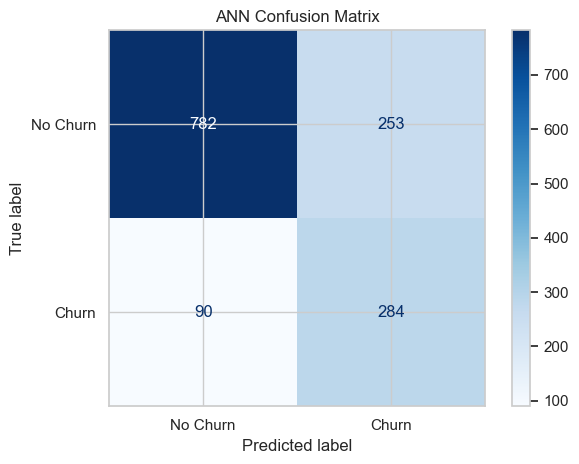

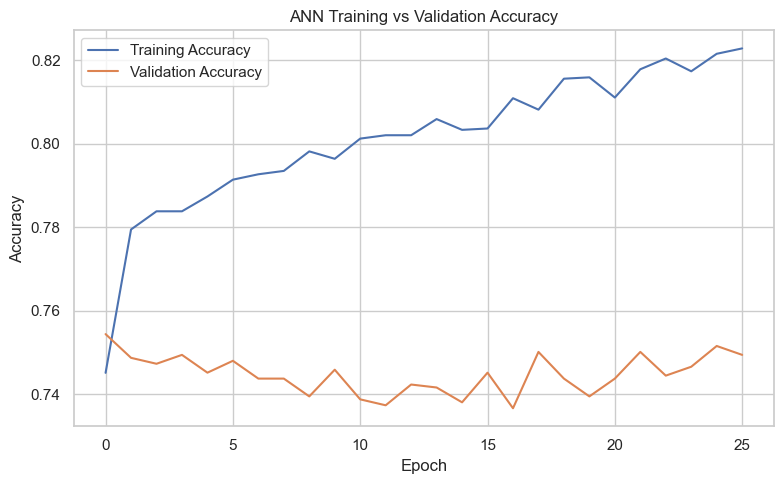

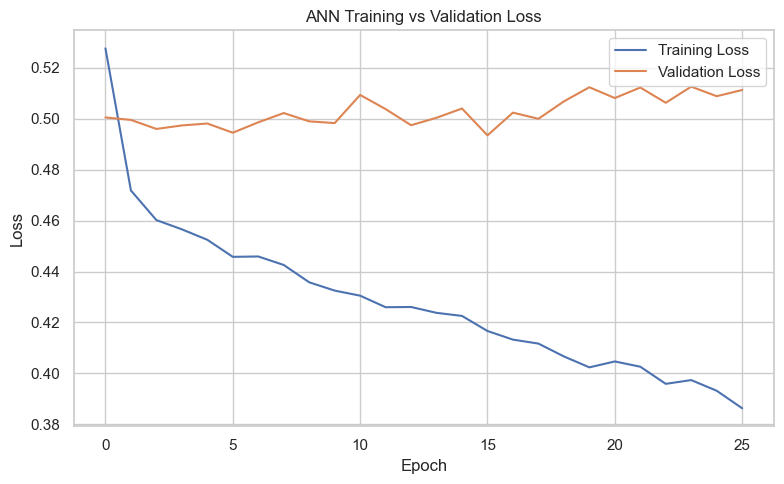

In [13]:
# ============================================================
# ANN FOR TELCO CUSTOMER CHURN PREDICTION
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

tf.keras.utils.set_random_seed(42)

# Build ANN Model
ann_model = Sequential([
    Input(shape=(X_train_balanced.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

# Compile Model
ann_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early Stopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train Model
history = ann_model.fit(
    X_train_balanced,
    y_train_balanced,
    validation_data=(X_val_processed, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

# Predict on Test Data
y_prob = ann_model.predict(X_test_processed).ravel()
y_pred = (y_prob >= 0.5).astype(int)

# Evaluate Model
print("\nANN MODEL PERFORMANCE")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)
plt.title("ANN Confusion Matrix")
plt.tight_layout()
plt.show()

# Training and Validation Accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

# Training and Validation Loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:

# ============================================================
# 11. FINAL EVALUATION ON THE UNSEEN TEST SET
# ============================================================

test_results = []
test_predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test_processed)
    y_prob = model.predict_proba(X_test_processed)[:, 1]

    test_predictions[name] = y_pred

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

test_results_df = pd.DataFrame(test_results)
test_results_df = test_results_df.sort_values(
    by="F1 Score", ascending=False
)

print("\nFINAL TEST RESULTS:")
print(test_results_df.round(4).to_string(index=False))




FINAL TEST RESULTS:
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.7466     0.5149  0.7834    0.6214   0.8414
           AdaBoost    0.7466     0.5152  0.7701    0.6174   0.8410
      Decision Tree    0.7559     0.5316  0.6738    0.5943   0.7750
K-Nearest Neighbors    0.6998     0.4591  0.7353    0.5653   0.7710
      Random Forest    0.7679     0.5666  0.5348    0.5502   0.8120



Best Model: AdaBoost

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.74      0.81      1035
       Churn       0.52      0.77      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.75      0.76      1409



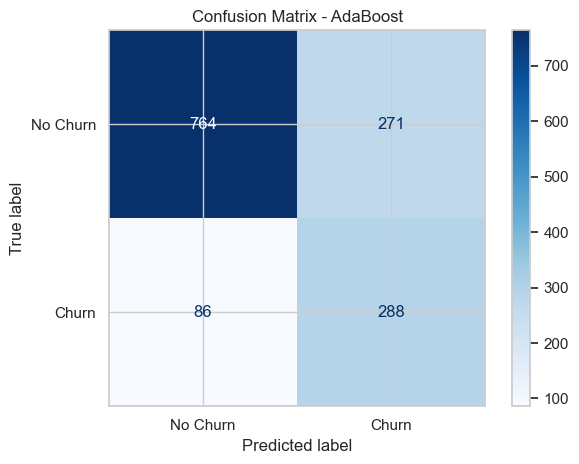

In [15]:

# ============================================================
# 12. CLASSIFICATION REPORT AND CONFUSION MATRIX
# ============================================================

y_best_pred = best_model.predict(X_test_processed)

print("\nBest Model:", best_model_name)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_best_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_best_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot(cmap="Blues", values_format="d")

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()



In [ ]:

# ============================================================
# 13. ROC CURVE COMPARISON
# ============================================================

plt.figure(figsize=(9, 7))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model, X_test_processed, y_test, name=name,
        ax=plt.gca()
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()



In [ ]:

# ============================================================
# 14. MODEL PERFORMANCE VISUALIZATION
# ============================================================

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

test_results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [ ]:


# ============================================================
# 15. CONCLUSION
# ============================================================

best_test_row = test_results_df.iloc[0]

print("\n" + "=" * 60)
print("PROJECT CONCLUSION")
print("=" * 60)

print("Best Model by Test F1 Score:", best_test_row["Model"])
print(f"Accuracy:  {best_test_row['Accuracy']:.4f}")
print(f"Precision: {best_test_row['Precision']:.4f}")
print(f"Recall:    {best_test_row['Recall']:.4f}")
print(f"F1 Score:  {best_test_row['F1 Score']:.4f}")
print(f"ROC-AUC:   {best_test_row['ROC-AUC']:.4f}")

print(
    "\nThe model with the highest test F1 score provides the best "
    "balance between precision and recall among the evaluated models. "
    "The final choice should also consider churn recall and ROC-AUC, "
    "since identifying customers likely to leave is important."
)